# Supplemental Figure 5, Panel H

Lineplots of log2FC expression (stimulus vs vehicle) at genes binned by PCHi-C contact distance and subsetted into genes that contact IFNg-induced cREs, Dex-induced cREs, or no inducible cREs

*Output: PanelH.pdf*

# Setup

In [1]:
# load packages

library(tidyverse)
library(RColorBrewer)
library(patchwork)
library(pheatmap)
library(rtracklayer)
library(GenomicRanges)
library(here)
here::i_am("figures/SuppFig5/PanelH/PanelH.ipynb")
theme_set(theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=15)))

sessionInfo()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required package: GenomicRanges

Loading required package: stats4

Loading required package: BiocGenerics


Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:lubridate’:

    intersect, setdiff, union


The following objects are masked from ‘package:dplyr’:

    combine, intersect, setdiff, union


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:b

R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] here_1.0.2           rtracklayer_1.58.0   GenomicRanges_1.50.2
 [4] GenomeInfoDb_1.34.9  IRanges_2.32.0       S4Vectors_0.36.2    
 [7] BiocGenerics_0.44.0  pheatmap_1.0.12      patchwork_1.3.0     
[10] RColorBrewer_1.1-3   lubridate_1.9.4      forcats_1.0.0       
[13] str

# Load differential expression and differential accessibility results

In [2]:
# ATAC-seq metadata
row_meta <- read.delim(
  here("inputs", "bed", "ATAC_peaks", "filtered", "consensus_filt_annot.tsv"),
  sep = "\t"
)

row_meta$ATAC_ID <- seq(1, nrow(row_meta))

# differential accessibility analysis results
dar_IFN_1h <- read.delim(
  here("inputs", "DARs", "GM12878_stimulus", "DAR_IFN_1h.tsv"),
  sep = "\t"
)

dar_IFN_6h <- read.delim(
  here("inputs", "DARs", "GM12878_stimulus", "DAR_IFN_6h.tsv"),
  sep = "\t"
)

dar_Dex_1h <- read.delim(
  here("inputs", "DARs", "GM12878_stimulus", "DAR_Dex_1h.tsv"),
  sep = "\t"
)

dar_Dex_6h <- read.delim(
  here("inputs", "DARs", "GM12878_stimulus", "DAR_Dex_6h.tsv"),
  sep = "\t"
)

dar_BRM_1h <- read.delim(
  here("inputs", "DARs", "time_1h_DARs.tsv"),
  sep = "\t"
) %>%
  arrange(seqnames, start)

dar_BRM_IFN_1h <- read.delim(
  here("inputs", "DARs", "GM12878_stimulus", "DAR_BRM_IFN_1h.tsv"),
  sep = "\t"
) %>%
  arrange(seqnames, start)

dar_BRM_IFN_6h <- read.delim(
  here("inputs", "DARs", "GM12878_stimulus", "DAR_BRM_IFN_6h.tsv"),
  sep = "\t"
) %>%
  arrange(seqnames, start)

dar_BRM_Dex_1h <- read.delim(
  here("inputs", "DARs", "GM12878_stimulus", "DAR_BRM_Dex_1h.tsv"),
  sep = "\t"
) %>%
  arrange(seqnames, start)

dar_BRM_Dex_6h <- read.delim(
  here("inputs", "DARs", "GM12878_stimulus", "DAR_BRM_Dex_6h.tsv"),
  sep = "\t"
) %>%
  arrange(seqnames, start)

# inducible gene metadata
ind_genes <- read.delim(
  here("figures", "Figure4", "Panel_F", "inducible_genes.tsv"),
  sep = "\t"
)


# Load PCHi-C data and liftOver to hg38

In [3]:
#read in promoter capture Hi-C contacts
contacts <- read.delim(
  here(
    "inputs", "PCHi-C",
    "TS5_GM12878_promoter-other_significant_interactions.txt"
  ),
  sep = "\t"
)

#clean up gene name
contacts <- contacts %>% mutate(Symbol_clean = gsub("-.*$", "", contacts$Symbol))

#calculate contact distances
promoters <- GRanges(seqnames=contacts$chr.bait, ranges=IRanges(start=contacts$start.bait, end=contacts$end.bait))
targets <- GRanges(seqnames=contacts$chr, ranges=IRanges(start=contacts$start, end=contacts$end))
distances <- distance(promoters,targets)
contacts$distance <- distances

#convert to GRanges format
contacts_gr <- contacts %>% select(seqnames=chr,start,end, Symbol_clean,distance,loe=log.observed.expected.) %>% mutate(ID=seq(1, nrow(contacts))) %>% makeGRangesFromDataFrame(keep.extra.columns = TRUE)

#lift over from hg19 to hg38
chain <- import.chain(
  here(
    "inputs", "PCHi-C",
    "hg19ToHg38.over.chain"
  )
)

contacts_gr_hg38 <- liftOver(contacts_gr, chain)
contacts_gr_hg38 <- unlist(contacts_gr_hg38)

# subset PCHiC contacts to include rows that overlap ATAC-seq peaks, and annotate with effect of induction on expression/accessibility and BAFinh effects

In [4]:

#find overlaps between ATAC-seq peaks and PCHi-C contacts
ol <- findOverlaps(contacts_gr_hg38, makeGRangesFromDataFrame(row_meta,keep.extra.columns = TRUE))
contacts_index <- queryHits(ol)
atac_index <- subjectHits(ol)

#for overlapping set, add metadata for inducibility and fold induction of chromatin accessibility
contacts_hg38_atac <- contacts_gr_hg38[contacts_index,] %>% data.frame() %>% 
    mutate(seqnames=row_meta[atac_index,]$seqnames, #coordinates of cREs
        start=row_meta[atac_index,]$start,
        end=row_meta[atac_index,]$end,
        width=row_meta[atac_index,]$width,
        TSS = row_meta[atac_index,]$TSS,
        type = row_meta[atac_index,]$type, #cRE type
        ATAC_ID=row_meta[atac_index,]$ATAC_ID, 
        fc_dex_atac=dar_Dex_6h[atac_index,]$logFC,
        ind_dex_atac=(dar_Dex_6h$change == "up" | dar_Dex_1h$change == "up")[atac_index],
        fc_ifn_atac=dar_IFN_6h[atac_index,]$logFC,
        ind_ifn_atac=(dar_IFN_6h$change == "up" | dar_IFN_1h$change == "up")[atac_index],
        fc_brm_dex_atac=dar_BRM_Dex_6h[atac_index,]$logFC,
        stim_repr_dex_atac= dar_BRM_Dex_6h[atac_index,]$change == "down",
        fc_brm_ifn_atac=dar_BRM_IFN_6h[atac_index,]$logFC,
        stim_repr_ifn_atac= dar_BRM_IFN_6h[atac_index,]$change == "down",
        fc_brm_atac=dar_BRM_1h[atac_index,]$logFC,
        )

#left join to add equivalent metadata at the RNA level
contacts_hg38_atac_rna <- left_join(contacts_hg38_atac, ind_genes %>% mutate(Symbol_clean = gene_symbol))

write.table(contacts_hg38_atac_rna, "GM12878_PCHi-C_ATAC_RNA.tsv", sep='\t', row.names=FALSE)

Joining with `by = join_by(Symbol_clean)`
Warning message in left_join(contacts_hg38_atac, ind_genes %>% mutate(Symbol_clean = gene_symbol)):
“Detected an unexpected many-to-many relationship between `x` and `y`.
ℹ Row 13080 of `x` matches multiple rows in `y`.
ℹ Row 8800 of `y` matches multiple rows in `x`.
ℹ If a many-to-many relationship is expected, set `relationship =
  "many-to-many"` to silence this warning.”


# Generate plots

In [5]:
dex_col <- "#5791c9"
ifn_col <- "#149e77"

p1 <- contacts_hg38_atac_rna %>% filter(!is.na(ifn_ind), !TSS)  %>% #only include genes assayed by RNA-seq and links between TSS-distal cREs and genes
    mutate(decile=ntile(distance,10)) %>% #bin contacts by cRE-gene distance
    mutate(group=case_when(ind_dex_atac==T ~ "Dex", ind_ifn_atac==T ~ "IFN", TRUE ~ "none")) %>% #classify based on whether ATAC peak is inducible by either or neither stimulus
    group_by(decile, group) %>% 
    summarize(dist=mean(distance), rnafc=mean(dex_6h_log2fc), sd=sd(dex_6h_log2fc), se=sd/sqrt(n())) %>% #calculate mean and SE of expression log2FC within each group for each decile
    ggplot(aes(x=dist,y=rnafc, color=group, alpha=group=="Dex")) + geom_hline(yintercept=0, linetype=2, color='grey') +  #plot
    geom_ribbon(aes(ymin=rnafc-se, ymax=rnafc+se, fill=group), width=.1, alpha=.1, linewidth=NA) + geom_line(linewidth=1) +
    scale_color_manual(values=c(Dex=dex_col, IFN=ifn_col, none="black"), name="") + scale_fill_manual(values=c(Dex=dex_col, IFN=ifn_col, none="black"), name="") + theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=15)) + ylab("log2FC RNA expression\nDex vs Vehicle") + 
    scale_alpha_manual(values=c(.25,1)) + scale_x_log10(breaks=c(25000,100000,500000))

p2 <- contacts_hg38_atac_rna %>% filter(!is.na(ifn_ind), !TSS) %>% mutate(decile=ntile(distance,10)) %>% mutate(group=case_when(ind_dex_atac==T ~ "Dex", ind_ifn_atac==T ~ "IFN", TRUE ~ "none")) %>% group_by(decile, group) %>%
    summarize(dist=mean(distance), rnafc=mean(ifn_6h_log2fc), sd=sd(ifn_6h_log2fc), se=sd/sqrt(n())) %>%
    ggplot(aes(x=dist,y=rnafc, color=group, alpha=group=="IFN")) + geom_hline(yintercept=0, linetype=2, color='grey') + 
    geom_ribbon(aes(ymin=rnafc-se, ymax=rnafc+se, fill=group), width=.1, alpha=.1, linewidth=NA) + geom_line(linewidth=1) +
    scale_color_manual(values=c(Dex=dex_col, IFN=ifn_col, none="black"), name="") + scale_fill_manual(values=c(Dex=dex_col, IFN=ifn_col, none="black"), name="")  + theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=15)) + ylab("log2FC RNA expression\nIFN vs Vehicle") +
    scale_alpha_manual(values=c(.25,1)) + scale_x_log10(breaks=c(25000,100000,500000))


`summarise()` has grouped output by 'decile'. You can override using the
`.groups` argument.
Warning message in geom_ribbon(aes(ymin = rnafc - se, ymax = rnafc + se, fill = group), :
“Ignoring unknown parameters: `width`”
`summarise()` has grouped output by 'decile'. You can override using the
`.groups` argument.
Warning message in geom_ribbon(aes(ymin = rnafc - se, ymax = rnafc + se, fill = group), :
“Ignoring unknown parameters: `width`”


# Assemble figure panel

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Saving 6 x 7 in image
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


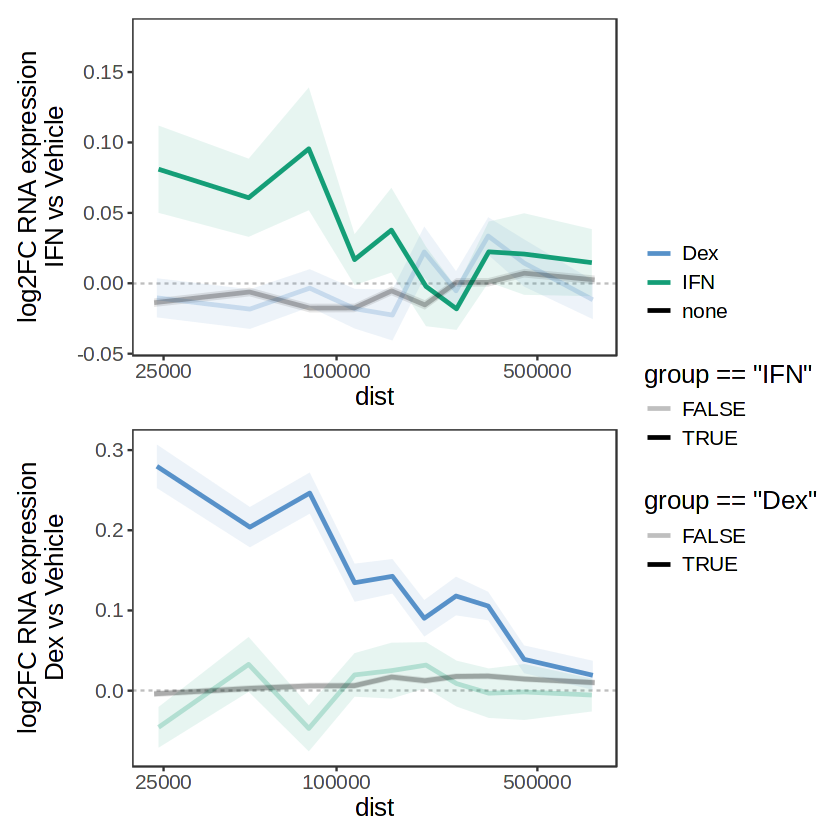

In [6]:
(p2 / p1) + plot_layout(guides="collect")
ggsave("PanelH.pdf", width=6)

# Statistics

In [7]:
#stats - wilcoxon rank sum test between log2FC at IFN-ind vs Dex-ind linked genes. Report p-values after adjusting for multiple testing using Benjamini-Hochberg method

#Dex RNA fc - Dex-ind vs IFN-ind ATAC
contacts_hg38_atac_rna %>% filter(!is.na(ifn_ind), !TSS)  %>% mutate(decile=ntile(distance,10)) %>% 
    mutate(group=case_when(ind_dex_atac==T ~ "Dex", ind_ifn_atac==T ~ "IFN", TRUE ~ "none")) %>%
    select(gene_symbol, decile, distance,group, dex_6h_log2fc) %>%
    filter(group!="none") %>% na.omit() %>%
    group_by(decile) %>%
    summarize(p=wilcox.test(dex_6h_log2fc ~ group)$p.value, .groups="drop") %>% mutate(p_adj=p.adjust(p, method="BH"), sig = p_adj < .05)

#IFN RNA fc - IFN-ind vs Dex-ind ATAC
contacts_hg38_atac_rna %>% filter(!is.na(ifn_ind), !TSS)  %>% mutate(decile=ntile(distance,10)) %>% 
    mutate(group=case_when(ind_dex_atac==T ~ "Dex", ind_ifn_atac==T ~ "IFN", TRUE ~ "none")) %>%
    select(gene_symbol, decile, distance,group, ifn_6h_log2fc) %>%
    filter(group!="none") %>% na.omit() %>%
    group_by(decile) %>%
    summarize(p=wilcox.test(ifn_6h_log2fc ~ group)$p.value, .groups="drop") %>% mutate(p_adj=p.adjust(p, method="BH"), sig = p_adj < .05)

decile,p,p_adj,sig
<int>,<dbl>,<dbl>,<lgl>
1,2.215072e-17,2.215072e-16,TRUE
2,1.359900e-04,2.266500e-04,TRUE
3,6.996856e-14,3.498428e-13,TRUE
4,8.439643e-05,1.687929e-04,TRUE
5,6.182900e-05,1.545725e-04,TRUE
6,1.376987e-02,1.967124e-02,TRUE
7,6.694918e-02,8.368647e-02,FALSE
8,8.526844e-06,2.842281e-05,TRUE
9,8.001490e-02,8.890545e-02,FALSE


decile,p,p_adj,sig
<int>,<dbl>,<dbl>,<lgl>
1,0.0004436810,0.002218405,TRUE
2,0.0001181619,0.001181619,TRUE
3,0.0013153292,0.004384431,TRUE
4,0.0296173819,0.059234764,FALSE
5,0.0183747622,0.045936905,TRUE
6,0.5906501927,0.732122814,FALSE
7,0.7092853784,0.732122814,FALSE
8,0.7321228136,0.732122814,FALSE
9,0.3707538629,0.529648376,FALSE


# Fisher's exact test for enrichment of links between inducible genes and inducible cREs

Warning message in geom_point(shape = 21, size = 5, color = "black", width = 0.5, :
“Ignoring unknown parameters: `width` and `linewidth`”


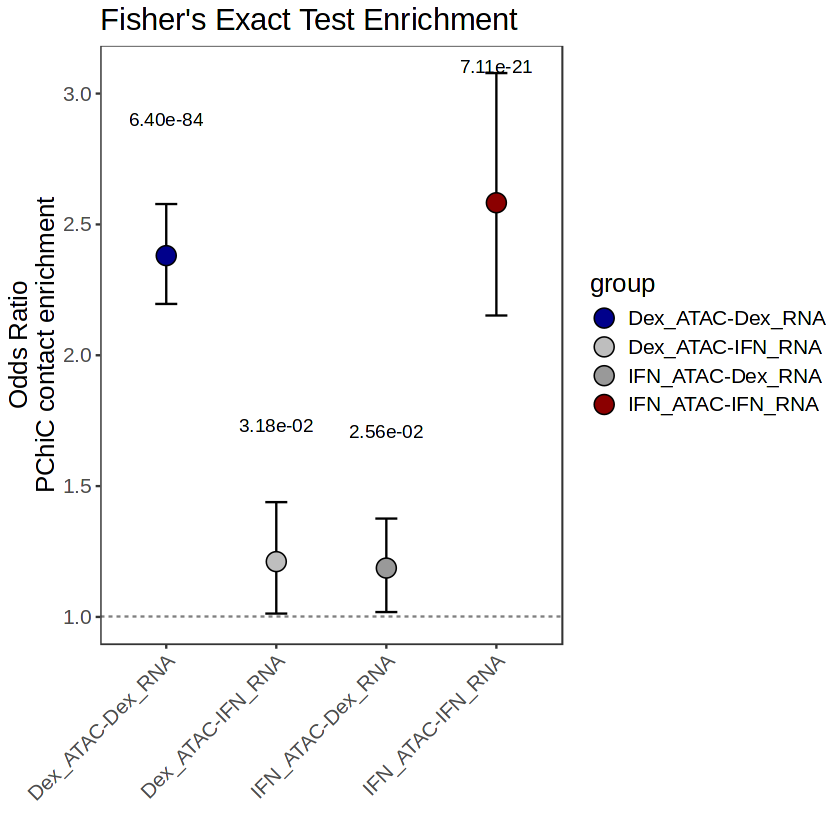

In [8]:
table_1 <- contacts_hg38_atac_rna %>% select(ind_ifn_atac, ifn_ind)   %>% table() 
table_2 <- contacts_hg38_atac_rna %>% select(ind_ifn_atac, dex_ind)  %>% table() 
table_3 <- contacts_hg38_atac_rna %>% select(ind_dex_atac, dex_ind)  %>% table()
table_4 <- contacts_hg38_atac_rna %>% select(ind_dex_atac, ifn_ind)  %>% table() 

ft1 <- fisher.test(table_1)
ft2 <- fisher.test(table_2)
ft3 <- fisher.test(table_3)
ft4 <- fisher.test(table_4)

# Convert to data frame
enrichment_df <- data.frame(
    group = c("IFN_ATAC-IFN_RNA", "IFN_ATAC-Dex_RNA", "Dex_ATAC-Dex_RNA", "Dex_ATAC-IFN_RNA"),
    OR = c(ft1$estimate,ft2$estimate, ft3$estimate, ft4$estimate),
    lower_CI = c(ft1$conf.int[1],ft2$conf.int[1], ft3$conf.int[1], ft4$conf.int[1]),
    upper_CI = c(ft1$conf.int[2],ft2$conf.int[2], ft3$conf.int[2],ft4$conf.int[2]),
    pval = c(ft1$p.value, ft2$p.value, ft3$p.value, ft4$p.value),
    geneset = c("Dex_ind", "IFN_ind")
)

# Plot
ggplot(enrichment_df, aes(x = group, y = OR, fill=group)) +
    geom_hline(yintercept = 1, linetype = "dashed", color = "gray50") +
    geom_errorbar(aes(ymin = lower_CI, ymax = upper_CI), width = 0.2) +
    geom_point(shape=21, size=5, color="black", width=.5, linewidth=1) +
    labs(
    y = "Odds Ratio\nPChiC contact enrichment",
    x = "",
    title = "Fisher's Exact Test Enrichment",
    #subtitle = paste0("p = ", signif(enrichment_df$pval, 3))
    ) +
    theme_bw()+ theme(text=element_text(size=15), panel.grid=element_blank(), axis.text.x=element_text(angle=45,hjust=1)) +
    geom_text(aes(label=format(pval, digits=3)), vjust=-10)  + scale_fill_manual(values=c("blue4", "grey", "grey60", "red4"))